In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 1) Nhập dữ liệu, thống kê các thông tin cơ bản, xử lý dữ liệu bị thiếu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn import metrics

# Nhập dữ liệu từ file csv
data = pd.read_csv('datasets/Mall_Customers.csv')

print("--- 5 dòng đầu tiên của bộ dữ liệu Mall Customers ---")
display(data.head())

print("\n--- Thông tin cấu trúc dữ liệu ---")
data.info()

print("\n--- Thống kê các chỉ số cơ bản ---")
display(data.describe())

print("\n--- Kiểm tra dữ liệu bị thiếu (Missing values) ---")
missing = data.isnull().sum()
print(missing)
if missing.sum() == 0:
    print("-> Bộ dữ liệu hoàn chỉnh, không có giá trị bị thiếu (Null/NaN).")
else:
    data = data.dropna()
    print("-> Đã loại bỏ các dòng có giá trị bị thiếu.")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- 5 dòng đầu tiên của bộ dữ liệu Mall Customers ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



--- Thông tin cấu trúc dữ liệu ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

--- Thống kê các chỉ số cơ bản ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



--- Kiểm tra dữ liệu bị thiếu (Missing values) ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
-> Bộ dữ liệu hoàn chỉnh, không có giá trị bị thiếu (Null/NaN).


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


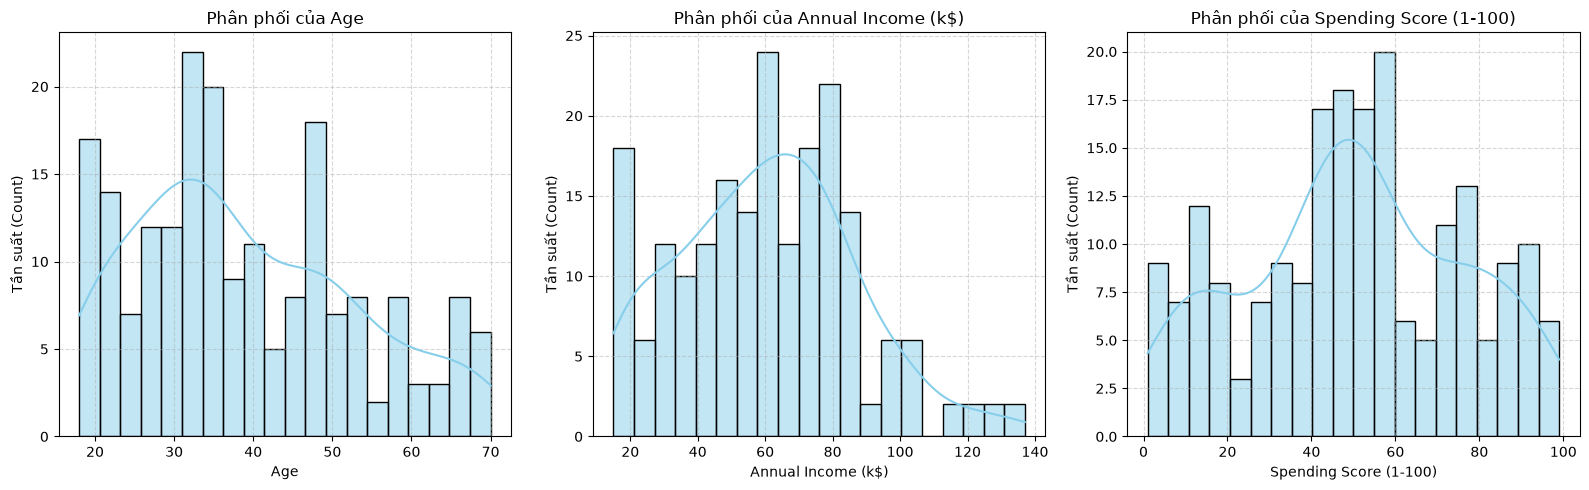

In [2]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 2) Sử dụng biểu đồ tần suất (Histogram) biểu diễn phân phối của Tuổi, Thu nhập hằng năm và Số điểm mua sắm
plt.figure(figsize=(16, 5))
cols_to_plot = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.histplot(data[col], bins=20, kde=True, color='skyblue', edgecolor='black')
    plt.title(f'Phân phối của {col}', fontsize=12)
    plt.xlabel(col)
    plt.ylabel('Tần suất (Count)')
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- Số lượng mẫu theo giới tính ---
Gender
Female    112
Male       88
Name: count, dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4992\3326823667.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, y='Gender', palette=['#1f77b4', '#ff7f0e'])


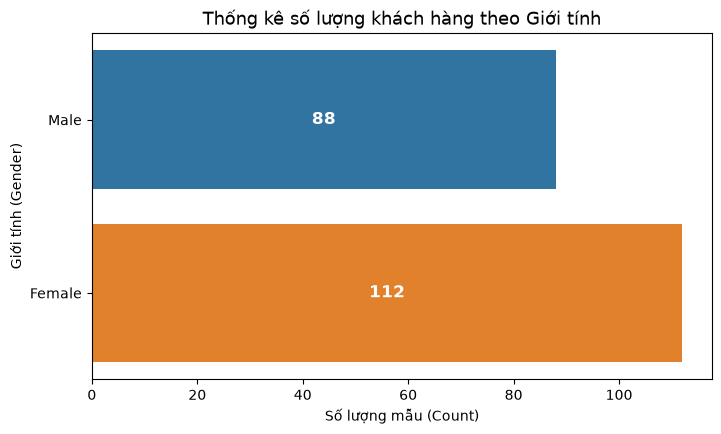

In [3]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 3) Thống kê số mẫu dữ liệu theo thuộc tính Giới tính
gender_counts = data['Gender'].value_counts()
print("--- Số lượng mẫu theo giới tính ---")
print(gender_counts)

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=data, y='Gender', palette=['#1f77b4', '#ff7f0e'])
plt.title('Thống kê số lượng khách hàng theo Giới tính', fontsize=13)
plt.xlabel('Số lượng mẫu (Count)')
plt.ylabel('Giới tính (Gender)')
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", 
                (p.get_width() / 2, p.get_y() + p.get_height() / 2), 
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


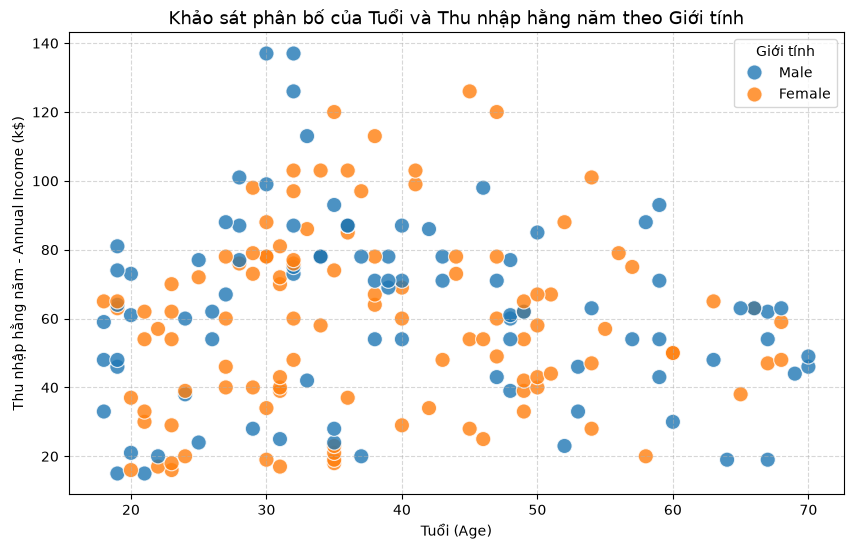

In [4]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 4) Sử dụng biểu đồ phân tán (Scatter plot) để khảo sát phân bố của Tuổi và Thu nhập hằng năm theo Giới tính
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data, 
    x='Age', 
    y='Annual Income (k$)', 
    hue='Gender', 
    s=120, 
    alpha=0.8,
    palette={'Male': '#1f77b4', 'Female': '#ff7f0e'}
)
plt.title('Khảo sát phân bố của Tuổi và Thu nhập hằng năm theo Giới tính', fontsize=13)
plt.xlabel('Tuổi (Age)')
plt.ylabel('Thu nhập hằng năm - Annual Income (k$)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Giới tính')
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


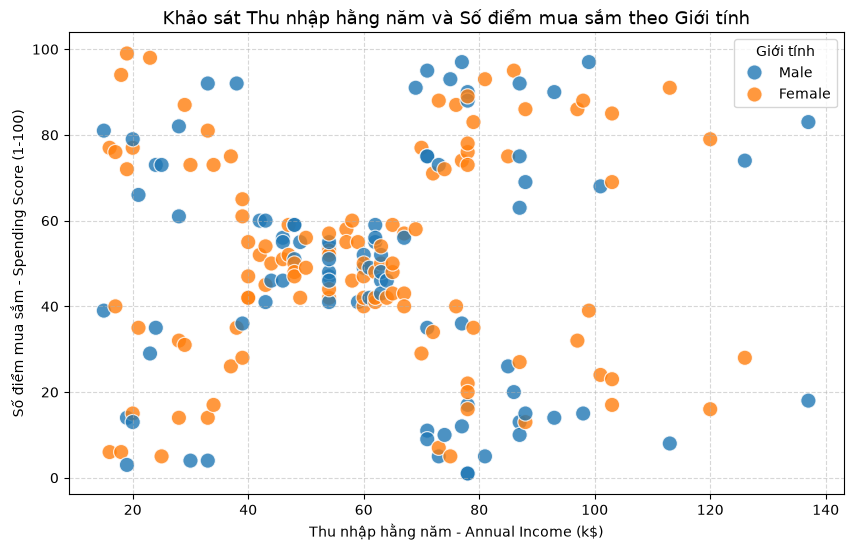

In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 5) Biểu đồ phân tán khảo sát thuộc tính Thu nhập hằng năm và Số điểm mua sắm theo Giới tính
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Gender', 
    s=120, 
    alpha=0.8,
    palette={'Male': '#1f77b4', 'Female': '#ff7f0e'}
)
plt.title('Khảo sát Thu nhập hằng năm và Số điểm mua sắm theo Giới tính', fontsize=13)
plt.xlabel('Thu nhập hằng năm - Annual Income (k$)')
plt.ylabel('Số điểm mua sắm - Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Giới tính')
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


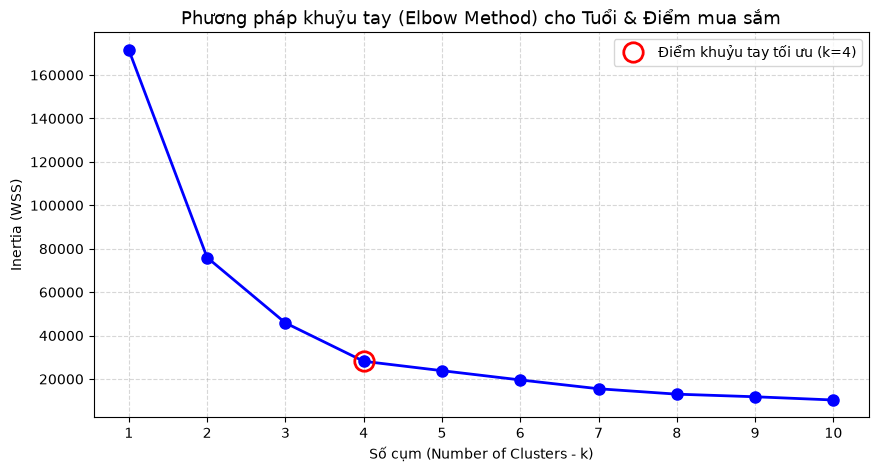

Đã hoàn thành gom cụm với k=4!
Tọa độ tâm cụm (Centroids):
 [[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]


In [6]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
    # Câu 6) Gom cụm theo Tuổi và Số điểm mua sắm bằng K-Means (ELBOW method xác định số cụm)
X1 = data[['Age', 'Spending Score (1-100)']].iloc[:, :].values
inertia1 = []

for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X1)
    inertia1.append(algorithm.inertia_)

# Vẽ biểu đồ Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), inertia1, 'bo-', linewidth=2, markersize=8)
plt.plot(4, inertia1[3], 'ro', markersize=14, markeredgewidth=2, fillstyle='none', label='Điểm khuỷu tay tối ưu (k=4)')
plt.title('Phương pháp khuỷu tay (Elbow Method) cho Tuổi & Điểm mua sắm', fontsize=13)
plt.xlabel('Số cụm (Number of Clusters - k)')
plt.ylabel('Inertia (WSS)')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Tiến hành gom cụm với k=4
k_opt1 = 4
kmeans1 = KMeans(n_clusters=k_opt1, init='random', n_init=10, random_state=42)
kmeans1.fit(X1)
labels1 = kmeans1.labels_
centroids1 = kmeans1.cluster_centers_
print(f"Đã hoàn thành gom cụm với k={k_opt1}!")
print("Tọa độ tâm cụm (Centroids):\n", centroids1)


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


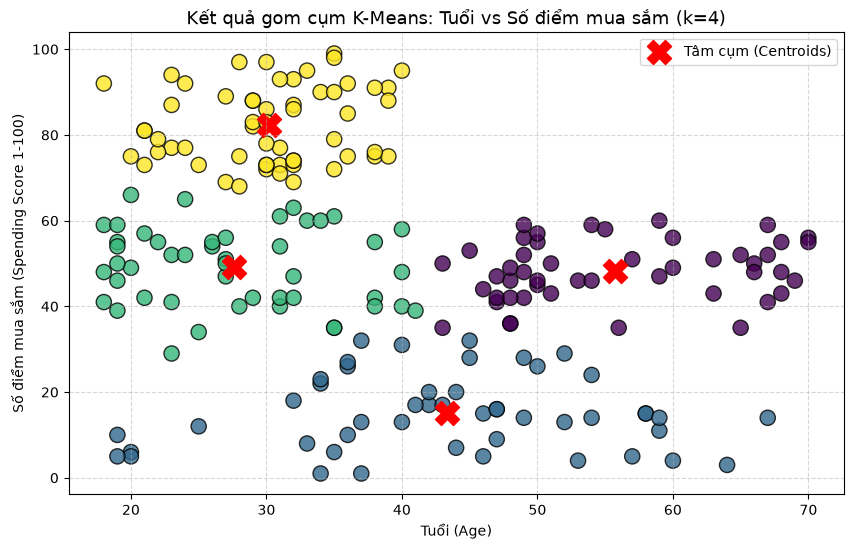

In [7]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 7) Biểu diễn kết quả gom cụm trên bằng biểu đồ
plt.figure(figsize=(10, 6))
plt.scatter(X1[:, 0], X1[:, 1], c=labels1, cmap='viridis', s=120, alpha=0.8, edgecolors='black')
plt.scatter(centroids1[:, 0], centroids1[:, 1], c='red', s=300, marker='X', label='Tâm cụm (Centroids)')
plt.title('Kết quả gom cụm K-Means: Tuổi vs Số điểm mua sắm (k=4)', fontsize=13)
plt.xlabel('Tuổi (Age)')
plt.ylabel('Số điểm mua sắm (Spending Score 1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


In [8]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 8) Đánh giá kết quả gom cụm bằng Hệ số Dáng điệu (Silhouette coefficient)
sil_score1 = metrics.silhouette_score(X1, labels1, metric='euclidean')
print(f"Hệ số Dáng điệu (Silhouette Coefficient) cho Tuổi & Số điểm mua sắm (k=4): {sil_score1:.4f}")

if sil_score1 > 0.5:
    print("-> Chất lượng phân cụm rất tốt (các cụm tách biệt rõ ràng).")
elif sil_score1 > 0.35:
    print("-> Chất lượng phân cụm ở mức khá tốt (cấu trúc cụm hợp lý).")
else:
    print("-> Chất lượng phân cụm ở mức trung bình.")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Hệ số Dáng điệu (Silhouette Coefficient) cho Tuổi & Số điểm mua sắm (k=4): 0.4997
-> Chất lượng phân cụm ở mức khá tốt (cấu trúc cụm hợp lý).


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
TRƯỜNG HỢP 1: GOM CỤM THEO THU NHẬP HẰNG NĂM VÀ SỐ ĐIỂM MUA SẮM


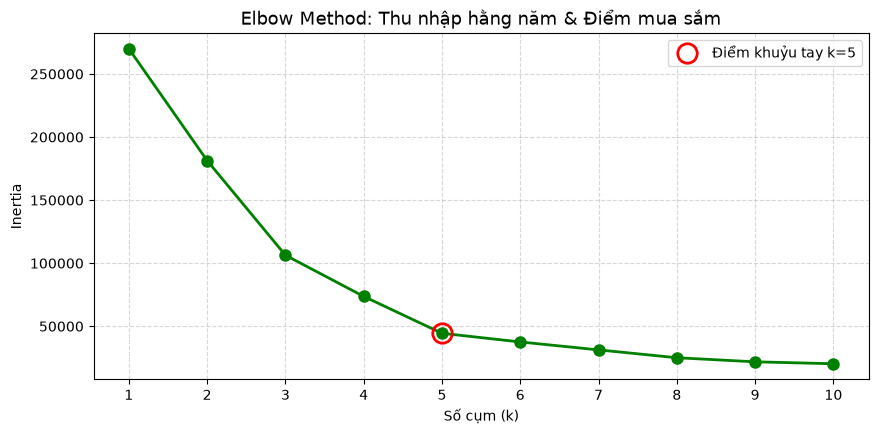

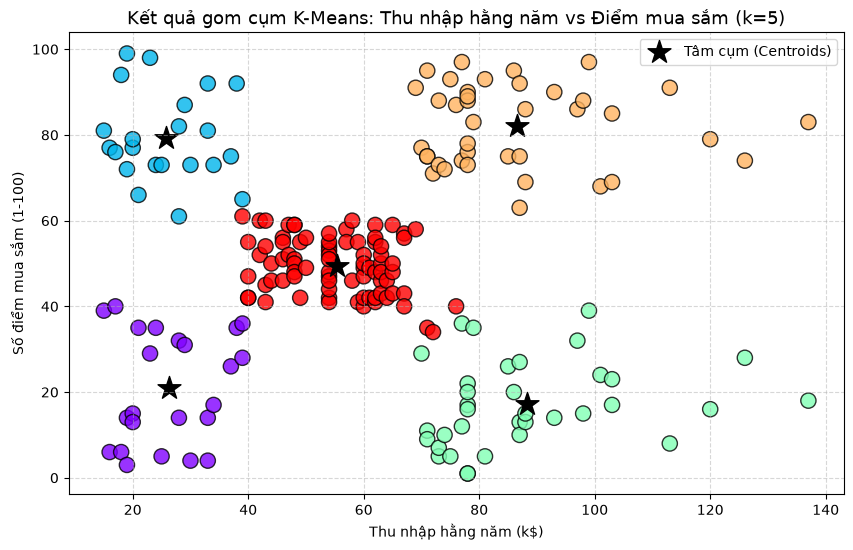

-> Hệ số Silhouette (Thu nhập & Điểm mua sắm, k=5): 0.5539

TRƯỜNG HỢP 2: GOM CỤM THEO TUỔI, THU NHẬP HẰNG NĂM VÀ SỐ ĐIỂM MUA SẮM (3D)
-> Hệ số Silhouette (Tuổi, Thu nhập & Điểm mua sắm, k=5): 0.4443


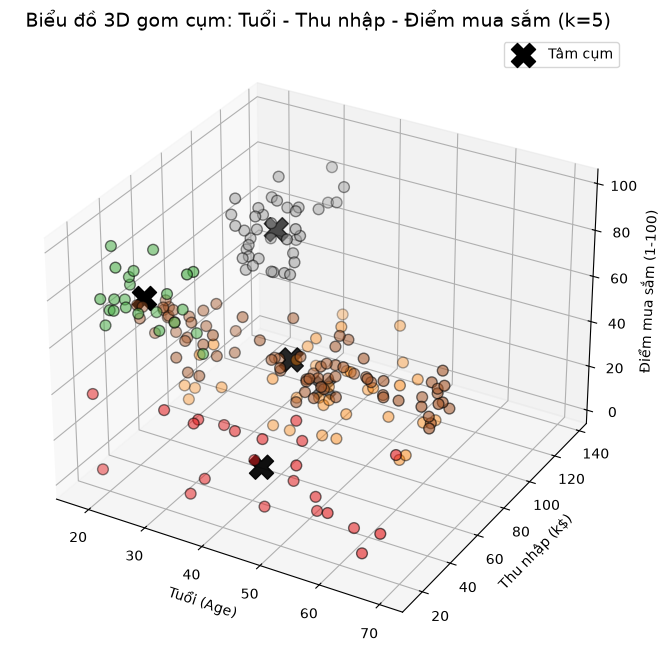

In [9]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu 9) Thực hiện tương tự câu 6-8 cho 2 trường hợp còn lại
print("==========================================================================")
print("TRƯỜNG HỢP 1: GOM CỤM THEO THU NHẬP HẰNG NĂM VÀ SỐ ĐIỂM MUA SẮM")
print("==========================================================================")
X2 = data[['Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
inertia2 = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    km.fit(X2)
    inertia2.append(km.inertia_)

plt.figure(figsize=(10, 4.5))
plt.plot(range(1, 11), inertia2, 'go-', linewidth=2, markersize=8)
plt.plot(5, inertia2[4], 'ro', markersize=14, markeredgewidth=2, fillstyle='none', label='Điểm khuỷu tay k=5')
plt.title('Elbow Method: Thu nhập hằng năm & Điểm mua sắm', fontsize=13)
plt.xlabel('Số cụm (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Huấn luyện với k=5
kmeans2 = KMeans(n_clusters=5, init='random', n_init=10, random_state=42)
labels2 = kmeans2.fit_predict(X2)
centroids2 = kmeans2.cluster_centers_

plt.figure(figsize=(10, 6))
plt.scatter(X2[:, 0], X2[:, 1], c=labels2, cmap='rainbow', s=120, alpha=0.8, edgecolors='black')
plt.scatter(centroids2[:, 0], centroids2[:, 1], c='black', s=300, marker='*', label='Tâm cụm (Centroids)')
plt.title('Kết quả gom cụm K-Means: Thu nhập hằng năm vs Điểm mua sắm (k=5)', fontsize=13)
plt.xlabel('Thu nhập hằng năm (k$)')
plt.ylabel('Số điểm mua sắm (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

sil_score2 = metrics.silhouette_score(X2, labels2)
print(f"-> Hệ số Silhouette (Thu nhập & Điểm mua sắm, k=5): {sil_score2:.4f}")

print("\n==========================================================================")
print("TRƯỜNG HỢP 2: GOM CỤM THEO TUỔI, THU NHẬP HẰNG NĂM VÀ SỐ ĐIỂM MUA SẮM (3D)")
print("==========================================================================")
X3 = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
kmeans3 = KMeans(n_clusters=5, init='random', n_init=10, random_state=42)
labels3 = kmeans3.fit_predict(X3)
centroids3 = kmeans3.cluster_centers_
sil_score3 = metrics.silhouette_score(X3, labels3)
print(f"-> Hệ số Silhouette (Tuổi, Thu nhập & Điểm mua sắm, k=5): {sil_score3:.4f}")

# Vẽ biểu đồ 3D bằng Matplotlib
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=labels3, cmap='Set1', s=60, alpha=0.8, edgecolors='k')
ax.scatter(centroids3[:, 0], centroids3[:, 1], centroids3[:, 2], c='black', s=300, marker='X', label='Tâm cụm')
ax.set_title('Biểu đồ 3D gom cụm: Tuổi - Thu nhập - Điểm mua sắm (k=5)', fontsize=14)
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Thu nhập (k$)')
ax.set_zlabel('Điểm mua sắm (1-100)')
plt.legend()
plt.show()

# Vẽ biểu đồ tương tác 3D bằng Plotly
import plotly.graph_objs as go
data['label3'] = labels3
trace1 = go.Scatter3d(
    x=data['Age'],
    y=data['Spending Score (1-100)'],
    z=data['Annual Income (k$)'],
    mode='markers',
    marker=dict(color=data['label3'], size=5, colorscale='Viridis', opacity=0.8)
)
layout = go.Layout(
    title='Biểu đồ tương tác 3D Plotly: Age - Spending Score - Annual Income',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    )
)
fig_plotly = go.Figure(data=[trace1], layout=layout)
fig_plotly.show()
